# Formative 2 – Task 1: Data Merge, Preprocessing & Product Recommendation


## Introduction

**Task:** Merge the customer transaction and social profile datasets, then use the combined data to predict which product category a customer is likely to buy.

**Goal and outcome:** This notebook produces the product-recommendation component of the face and voice verification system. It delivers a cleaned, merged and feature-engineered dataset, a trained model whose performance is evaluated with accuracy, macro F1 and log loss, and a `predict_product(customer_id)` function that the final command-line app calls once a user has been verified.

---
## 1. Setup and load data

### 1.1 Import libraries

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, f1_score, log_loss, make_scorer, top_k_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed -> GradientBoostingClassifier will be used instead (pip install xgboost).")

### 1.2 Mount Google Drive and set up folders
The data is loaded from **Google Drive**, so nothing has to be uploaded in each session.
Everything the notebook produces (merged dataset, model, metrics, figures) is saved back into the same Drive folder, so it survives when Colab resets.

In [2]:
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DRIVE_PROJECT_DIR = "/content/drive/MyDrive/formative2"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(DRIVE_PROJECT_DIR)
    print("Running in Colab - using Google Drive folder:", ROOT)
except ImportError:
    ROOT = Path("..") if Path("../data").exists() else Path(".")
    print("Not running in Colab - using local folder:", ROOT.resolve())

CANDIDATE_DIRS = [ROOT / "data" / "raw", Path("data/raw"), Path(".")]
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR     = ROOT / "models"
FIG_DIR       = ROOT / "outputs" / "figures"
EVAL_DIR      = ROOT / "outputs" / "evaluation"
for d in (PROCESSED_DIR, MODEL_DIR, FIG_DIR, EVAL_DIR):
    d.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
Running in Colab - using Google Drive folder: /content/drive/MyDrive/formative2


### 1.3 Helper functions
- `find_file` looks for `<name>.csv` or `<name>.xlsx` in the candidate folders.
- `load_table` loads it and prints its size.
- `save_fig` saves every plot to `outputs/figures/` so the figures can be reused if needed.

In [3]:
def find_file(stem):
    for d in CANDIDATE_DIRS:
        for ext in (".csv", ".xlsx"):
            p = d / f"{stem}{ext}"
            if p.exists():
                return p
    raise FileNotFoundError(f"Could not find {stem}.csv or {stem}.xlsx. Put it in: {ROOT / 'data' / 'raw'}")

def load_table(stem):
    path = find_file(stem)
    df = pd.read_csv(path) if path.suffix == ".csv" else pd.read_excel(path)
    print(f"Loaded {path}  ->  {df.shape[0]} rows x {df.shape[1]} columns")
    return df

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 1.4 Load the transactions dataset
`customer_transactions` holds one row per purchase and contains the **target** (`product_category`).

In [4]:
trans_raw = load_table("customer_transactions")

Loaded /content/drive/MyDrive/formative2/data/raw/customer_transactions.xlsx  ->  150 rows x 6 columns


**Interpretation:**

The transactions file has **150 rows and 6 columns**. Each row is one purchase: transaction ID, customer ID, purchase amount, purchase date, product category (the target) and customer rating.

### 1.5 Load the social profiles dataset
`customer_social_profiles` holds social-media behaviour per customer (platform, engagement, interest, sentiment).

In [5]:
social_raw = load_table("customer_social_profiles")

Loaded /content/drive/MyDrive/formative2/data/raw/customer_social_profiles.xlsx  ->  155 rows x 5 columns


**Interpretation:**

The social profiles file has **155 rows and 5 columns**, slightly more than the transactions file. Each row is one social-media record for a customer: platform, engagement score, purchase-interest score and review sentiment.

---
## 2. Inspect the raw data
Before changing anything, look at the data as it is: first rows, data types, missing values, duplicates and the number of unique values.

### 2.1 Transactions – first rows
A first look at the columns and example values.

In [6]:
print("Transactions (first 5 rows):")
display(trans_raw.head())

Transactions (first 5 rows):


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


### 2.2 Transactions – data types, missing values, duplicates
One table summarising each column's type, number/percentage of missing values and number of unique values, plus the count of exact duplicate rows.

In [7]:
display(pd.DataFrame({
    "dtype": trans_raw.dtypes.astype(str),
    "missing": trans_raw.isna().sum(),
    "missing_%": (trans_raw.isna().mean() * 100).round(1),
    "unique": trans_raw.nunique(),
}))
print("Exact duplicate rows:", trans_raw.duplicated().sum())
print("Unique customers:", trans_raw["customer_id_legacy"].nunique())

,dtype,missing,missing_%,unique
customer_id_legacy,int64,0,0.0,75
transaction_id,int64,0,0.0,150
purchase_amount,int64,0,0.0,120
purchase_date,datetime64[ns],0,0.0,150
product_category,object,0,0.0,5
customer_rating,float64,10,6.7,37


Exact duplicate rows: 0
Unique customers: 75


**Interpretation:**

Only `customer_rating` has missing values (**10 rows, 6.7%**). There are no duplicate rows. The 150 unique transaction IDs belong to only **75 unique customers**, so customers buy several times (2 purchases on average). The target has 5 categories.

### 2.3 Social profiles – first rows
Same first look for the social data. Pay attention to how the customer ID is written.

In [8]:
print("\nSocial profiles (first 5 rows):")
display(social_raw.head())


Social profiles (first 5 rows):


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


### 2.4 Social profiles – data types, missing values, duplicates
Same summary table as for the transactions.

In [9]:
display(pd.DataFrame({
    "dtype": social_raw.dtypes.astype(str),
    "missing": social_raw.isna().sum(),
    "missing_%": (social_raw.isna().mean() * 100).round(1),
    "unique": social_raw.nunique(),
}))
print("Exact duplicate rows:", social_raw.duplicated().sum())
print("Unique customers:", social_raw["customer_id_new"].nunique())

,dtype,missing,missing_%,unique
customer_id_new,object,0,0.0,84
social_media_platform,object,0,0.0,5
engagement_score,int64,0,0.0,50
purchase_interest_score,float64,0,0.0,40
review_sentiment,object,0,0.0,3


Exact duplicate rows: 5
Unique customers: 84


**Interpretation:**

No missing values, but **5 exact duplicate rows**. The 155 rows cover only 84 customers, so customers repeat. The ID is text (A178), unlike the numeric ID in the transactions, so it must be converted before the merge.

### 2.5 Compare the two ID columns
The two files name the customer ID differently (`customer_id_legacy` vs `customer_id_new`). Looking at example values side by side shows why they cannot be joined directly.

In [10]:
print("Transactions ID column :", trans_raw["customer_id_legacy"].dtype, "| examples:", trans_raw["customer_id_legacy"].head(5).tolist())
print("Social ID column       :", social_raw["customer_id_new"].dtype,    "| examples:", social_raw["customer_id_new"].head(5).tolist())

Transactions ID column : int64 | examples: [151, 192, 114, 171, 160]
Social ID column       : object | examples: ['A178', 'A190', 'A150', 'A162', 'A197']


**Interpretation:**

The two ID columns cannot be compared as they are: one is an integer (`int64`) and the other is text with an `A` prefix. Stripping the prefix and converting to an integer makes the social IDs match the transactions IDs, so they can serve as the join key.

---
## 3. Clean the data
Cleaning steps are counted in a `log` dictionary so they can be reported.

> **Missing values are not filled here.** Imputing before splitting the data would leak information from the test set, so missing numeric values are imputed later *inside the modelling pipeline* (fitted on training data only).

### 3.1 Transactions – rename the key and fix data types
- Rename `customer_id_legacy` -> `customer_id` (the common name used after the merge).
- Make sure numeric columns are numeric and `purchase_date` is a real date (Excel serial numbers are converted if needed).

In [11]:
log = {}

trans = trans_raw.copy().rename(columns={"customer_id_legacy": "customer_id"})
for c in ["customer_id", "transaction_id", "purchase_amount", "customer_rating"]:
    trans[c] = pd.to_numeric(trans[c], errors="coerce")

if pd.api.types.is_numeric_dtype(trans["purchase_date"]):          # Excel serial numbers
    trans["purchase_date"] = pd.to_datetime(trans["purchase_date"], unit="D", origin="1899-12-30")
else:
    trans["purchase_date"] = pd.to_datetime(trans["purchase_date"], errors="coerce")

print(trans.dtypes)

customer_id                  int64
transaction_id               int64
purchase_amount              int64
purchase_date       datetime64[ns]
product_category            object
customer_rating            float64
dtype: object


**Interpretation:**

All columns now have suitable types: integer IDs, a float rating and a proper datetime for `purchase_date`. `purchase_amount` was read as an integer and is converted to a float in step 3.4.

### 3.2 Transactions – standardise text and drop rows without essential fields
- Trim spaces and fix capitalisation of `product_category` so that e.g. `" sports"` and `"Sports"` become one category.
- Drop rows where an essential field (customer, transaction, date, or the **target**) is missing – a row without a target cannot be used for training.

In [12]:
trans["product_category"] = trans["product_category"].astype(str).str.strip().str.title()

n0 = len(trans)
trans = trans.dropna(subset=["customer_id", "transaction_id", "purchase_date", "product_category"])
log["trans_rows_dropped_missing_key_fields"] = n0 - len(trans)

print("Rows dropped:", log["trans_rows_dropped_missing_key_fields"])
print(trans["product_category"].value_counts())

Rows dropped: 0
product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25
Name: count, dtype: int64


**Interpretation:**

No rows were dropped, because no essential field (customer, transaction, date or target) was missing. The five product categories are clean and consistent.

### 3.3 Transactions – validate ratings and amounts
- A rating must be between 1 and 5; values outside that range are **set to missing** (not deleted).
- A purchase amount must be positive; rows with zero, negative or missing amounts are dropped.

In [13]:
bad_rating = trans["customer_rating"].notna() & ~trans["customer_rating"].between(1, 5)
trans.loc[bad_rating, "customer_rating"] = np.nan
log["trans_out_of_range_ratings_set_to_nan"] = int(bad_rating.sum())

nonpos = trans["purchase_amount"].isna() | (trans["purchase_amount"] <= 0)
log["trans_nonpositive_or_missing_amount_dropped"] = int(nonpos.sum())
trans = trans[~nonpos]

print("Out-of-range ratings set to NaN :", log["trans_out_of_range_ratings_set_to_nan"])
print("Non-positive/missing amounts    :", log["trans_nonpositive_or_missing_amount_dropped"])
print("Remaining missing ratings       :", int(trans["customer_rating"].isna().sum()))

Out-of-range ratings set to NaN : 0
Non-positive/missing amounts    : 0
Remaining missing ratings       : 10


**Interpretation:**

No ratings fell outside the 1–5 range and no amount was zero, negative or missing, so nothing was changed. The **10 missing ratings remain** on purpose; they are imputed later inside the modelling pipeline so the test set cannot leak into the imputation.

### 3.4 Transactions – remove duplicates and finalise types
Drop exact duplicate rows and duplicate `transaction_id`s (a transaction ID must be unique), then convert ID columns to integers and reset the index.

In [14]:
n1 = len(trans)
trans = trans.drop_duplicates().drop_duplicates(subset="transaction_id")
log["trans_duplicates_dropped"] = n1 - len(trans)

trans[["customer_id", "transaction_id"]] = trans[["customer_id", "transaction_id"]].astype(int)
trans["purchase_amount"] = trans["purchase_amount"].astype(float)
trans = trans.reset_index(drop=True)

print(f"Transactions: {len(trans_raw)} raw rows -> {len(trans)} clean rows")
display(trans.head())

Transactions: 150 raw rows -> 150 clean rows


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408.0,2024-01-01,Sports,2.3
1,192,1002,332.0,2024-01-02,Electronics,4.2
2,114,1003,442.0,2024-01-03,Electronics,2.1
3,171,1004,256.0,2024-01-04,Clothing,2.8
4,160,1005,64.0,2024-01-05,Clothing,1.3


**Interpretation:**

No duplicate rows or duplicate transaction IDs were found, so the transactions stay at **150 rows**. The ID columns are now integers and the purchase amount is a float.

### 3.5 Social profiles – extract a numeric customer ID
`customer_id_new` looks like `A178`. A regular expression extracts the digits (`178`) so it matches the transactions' `customer_id`. Rows without a valid ID are dropped.

In [15]:
social = social_raw.copy()
social["customer_id"] = pd.to_numeric(
    social["customer_id_new"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
for c in ["engagement_score", "purchase_interest_score"]:
    social[c] = pd.to_numeric(social[c], errors="coerce")

n0 = len(social)
social = social.dropna(subset=["customer_id"])
log["social_rows_dropped_no_valid_id"] = n0 - len(social)

display(social[["customer_id_new", "customer_id"]].drop_duplicates().head())
print("Rows dropped (no valid ID):", log["social_rows_dropped_no_valid_id"])

,customer_id_new,customer_id
0,A178,178
1,A190,190
2,A150,150
3,A162,162
4,A197,197


Rows dropped (no valid ID): 0


**Interpretation:**

The regular expression extracted the numbers correctly (for example `A178` became 178, `A190` became 190). No rows were dropped for an invalid ID.

### 3.6 Social profiles – standardise text categories
Trim spaces and unify capitalisation of platform and sentiment names (keeping brand spellings such as `LinkedIn` and `TikTok`), so the same category is never counted twice under different spellings.

In [16]:
CANON = {"linkedin": "LinkedIn", "tiktok": "TikTok"}          # keep brand capitalisation
social["social_media_platform"] = (social["social_media_platform"].astype(str).str.strip()
                                   .map(lambda x: CANON.get(x.lower(), x.title())))
social["review_sentiment"] = social["review_sentiment"].astype(str).str.strip().str.title()

print("Platforms :", social["social_media_platform"].value_counts().to_dict())
print("Sentiments:", social["review_sentiment"].value_counts().to_dict())

Platforms : {'Twitter': 38, 'LinkedIn': 32, 'TikTok': 32, 'Facebook': 27, 'Instagram': 26}
Sentiments: {'Positive': 63, 'Neutral': 50, 'Negative': 42}


**Interpretation:**

Platform and sentiment names are consistent, with no duplicate spellings. There are five platforms (Twitter 38, LinkedIn 32, TikTok 32, Facebook 27, Instagram 26 records) and three sentiments (Positive 63, Neutral 50, Negative 42). Brand capitalisation such as `LinkedIn` and `TikTok` was kept. These counts are before the duplicates are removed in 3.8.

### 3.7 Social profiles – validate score ranges
Engagement should be 0–100 and purchase interest 1–5. Values outside these ranges are set to missing (and later imputed).

In [17]:
bad_eng = social["engagement_score"].notna() & ~social["engagement_score"].between(0, 100)
bad_int = social["purchase_interest_score"].notna() & ~social["purchase_interest_score"].between(1, 5)
social.loc[bad_eng, "engagement_score"] = np.nan
social.loc[bad_int, "purchase_interest_score"] = np.nan
log["social_out_of_range_scores_set_to_nan"] = int(bad_eng.sum() + bad_int.sum())

print("Out-of-range scores set to NaN:", log["social_out_of_range_scores_set_to_nan"])
print(social[["engagement_score", "purchase_interest_score"]].describe().round(2))

Out-of-range scores set to NaN: 0
       engagement_score  purchase_interest_score
count            155.00                   155.00
mean              75.61                     3.15
std               14.57                     1.14
min               50.00                     1.00
25%               63.50                     2.35
50%               77.00                     3.20
75%               87.50                     4.10
max               99.00                     5.00


**Interpretation:**

All scores are inside their valid ranges, so none were set to missing. Engagement runs from 50 to 99 (mean about 75.6) and purchase interest from 1.0 to 5.0 (mean about 3.15).

### 3.8 Social profiles – remove exact duplicates
Exact duplicate rows add no information and would bias the averages calculated later.

In [18]:
n1 = len(social)
social = social.drop_duplicates()
log["social_exact_duplicates_dropped"] = n1 - len(social)
social["customer_id"] = social["customer_id"].astype(int)
social = social.reset_index(drop=True)

print(f"Social profiles: {len(social_raw)} raw rows -> {len(social)} clean rows "
      f"({log['social_exact_duplicates_dropped']} duplicates removed)")

Social profiles: 155 raw rows -> 150 clean rows (5 duplicates removed)


**Interpretation:**

**5 exact duplicate rows** were found and removed (155 to 150 rows). Left in, these customers would have counted twice and distorted the per-customer averages calculated later.

### 3.9 Cleaning summary
All cleaning actions in one place – useful as a table in the report.

In [19]:
print("Cleaning log:")
for k, v in log.items():
    print(f"  {k:48s} {v}")
print(f"\nTransactions: {len(trans_raw)} -> {len(trans)} rows | Social: {len(social_raw)} -> {len(social)} rows")
print("Missing values left in transactions:\n", trans.isna().sum()[lambda s: s > 0].to_string())

Cleaning log:
  trans_rows_dropped_missing_key_fields            0
  trans_out_of_range_ratings_set_to_nan            0
  trans_nonpositive_or_missing_amount_dropped      0
  trans_duplicates_dropped                         0
  social_rows_dropped_no_valid_id                  0
  social_out_of_range_scores_set_to_nan            0
  social_exact_duplicates_dropped                  5

Transactions: 150 -> 150 rows | Social: 155 -> 150 rows
Missing values left in transactions:
 customer_rating    10


**Interpretation:**

The data was already fairly clean. The only fixes were: 5 duplicate social rows removed, the two customer ID formats unified, and text standardised. Nothing was dropped from the transactions. The **10 missing ratings (6.7%) were deliberately left as missing** and are imputed inside the model pipeline (median for numeric features, most frequent value for categorical ones, fitted on training data only) to avoid test-set leakage.

---
## 4. Choose the join key and join method
After cleaning, `trans.customer_id` and `social.customer_id` are both integers, so they can serve as the join key. Before merging, check how the two customer sets overlap and what a naive join would do.

### 4.1 How well do the two customer sets overlap?
Counts the customers in each file, in both, and in only one. This decides which join type makes sense.

In [20]:
t_ids, s_ids = set(trans["customer_id"]), set(social["customer_id"])
print(f"Customers in transactions : {len(t_ids)}")
print(f"Customers in social       : {len(s_ids)}")
print(f"In both                   : {len(t_ids & s_ids)}")
print(f"Transactions only         : {len(t_ids - s_ids)}")
print(f"Social only               : {len(s_ids - t_ids)}")
print("\nMax transactions per customer:", trans["customer_id"].value_counts().max())
print("Max social rows per customer :", social["customer_id"].value_counts().max())

Customers in transactions : 75
Customers in social       : 84
In both                   : 61
Transactions only         : 14
Social only               : 23

Max transactions per customer: 6
Max social rows per customer : 6


**Interpretation:**

**61 customers appear in both files**, 14 only in the transactions and 23 only in the social profiles. A customer can have up to 6 transactions and up to 6 social records, so the key is not unique in either table. The 14 transaction-only customers will have no social information, and the 23 social-only customers have no purchase (no target).

### 4.2 What happens with a naive join?
A customer has *several* transactions **and** *several* social records (a many-to-many relationship). Joining the raw tables multiplies rows. This cell demonstrates the problem.

In [21]:
naive = trans.merge(social, on="customer_id", how="left")
print(f"Naive left join: {len(trans)} transactions -> {len(naive)} rows  (row inflation!)")

Naive left join: 150 transactions -> 246 rows  (row inflation!)


**Interpretation:**

Joining the raw tables multiplies rows: **150 transactions become 246 rows**. Each transaction (and its target label) is repeated for every social record of the customer, which would bias training and make evaluation metrics misleading. The social data must therefore be aggregated to one row per customer before the merge.

### Decision: aggregate first, then left-join
1. **Aggregate the social profiles to one row per customer** (mean engagement/interest, most frequent platform, sentiment proportions, number of records).
2. **Left-join** the aggregated profiles onto the transactions using `customer_id`.

**Why a left join from transactions?** Each transaction holds the **target**, so every transaction must remain a training example. An inner join would throw away transactions whose customers have no social profile; an outer/right join would add social-only customers that have no target. Missing social data is handled with a `has_social_profile` flag plus imputation inside the pipeline.

---
## 5. Merge and validate

### 5.1 Aggregate social data – numeric and categorical summaries
One row per customer: average engagement and interest, the customer's most frequent platform, number of distinct platforms and number of social records.

In [22]:
def mode_or_nan(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

social_num = social.groupby("customer_id").agg(
    avg_engagement=("engagement_score", "mean"),
    avg_interest=("purchase_interest_score", "mean"),
    top_platform=("social_media_platform", mode_or_nan),
    n_platforms=("social_media_platform", "nunique"),
    n_social_records=("customer_id", "size"),
).reset_index()
display(social_num.head())
print("Shape:", social_num.shape)

,customer_id,avg_engagement,avg_interest,top_platform,n_platforms,n_social_records
0,100,77.000000,4.400000,Instagram,2,2
1,101,68.000000,1.000000,Twitter,1,1
2,102,51.000000,4.800000,LinkedIn,1,1
3,103,64.333333,2.866667,Instagram,2,3
4,104,83.000000,2.933333,Twitter,2,3


Shape: (84, 6)


**Interpretation:**

The social data now has exactly **one row per customer (84 customers)**. For example, customer 100 has 2 records on 2 platforms, with an average engagement of 77 and an average interest of 4.4. The most frequent platform is kept as `top_platform`.

### 5.2 Aggregate social data – sentiment shares
For each customer, the **proportion** of their reviews that are Positive, Neutral and Negative (the three values sum to 1).

In [23]:
sent = (pd.crosstab(social["customer_id"], social["review_sentiment"], normalize="index")
          .reindex(columns=["Positive", "Neutral", "Negative"], fill_value=0)
          .add_prefix("pct_").reset_index())
display(sent.head())

review_sentiment,customer_id,pct_Positive,pct_Neutral,pct_Negative
0,100,0.000000,0.500000,0.500000
1,101,0.000000,1.000000,0.000000
2,102,0.000000,1.000000,0.000000
3,103,0.666667,0.000000,0.333333
4,104,0.000000,0.333333,0.666667


**Interpretation:**

These are each customer's shares of Positive, Neutral and Negative reviews; they add up to 1. For example, customer 101 has `pct_Neutral` = 1.0 (all reviews neutral), and customer 100 is split 50% neutral and 50% negative.

### 5.3 Combine into one customer-level social table
Joins the two aggregated tables and confirms the key is unique, which is required for a safe many-to-one merge.

In [24]:
social_agg = social_num.merge(sent, on="customer_id", how="left")
print("Shape:", social_agg.shape, "| customer_id unique:", social_agg["customer_id"].is_unique)
display(social_agg.head())

Shape: (84, 9) | customer_id unique: True


,customer_id,avg_engagement,avg_interest,top_platform,n_platforms,n_social_records,pct_Positive,pct_Neutral,pct_Negative
0,100,77.000000,4.400000,Instagram,2,2,0.000000,0.500000,0.500000
1,101,68.000000,1.000000,Twitter,1,1,0.000000,1.000000,0.000000
2,102,51.000000,4.800000,LinkedIn,1,1,0.000000,1.000000,0.000000
3,103,64.333333,2.866667,Instagram,2,3,0.666667,0.000000,0.333333
4,104,83.000000,2.933333,Twitter,2,3,0.000000,0.333333,0.666667


**Interpretation:**

The combined customer-level social table has **84 rows and 9 columns**, and `customer_id` is unique (`True`). That makes the many-to-one merge with the transactions safe.

### 5.4 Merge social features onto the transactions
A **left join** keeps all transactions. `validate="many_to_one"` makes pandas raise an error if the social table still contained duplicate customers. A `has_social_profile` flag records whether a social profile was found; missing platforms are labelled `Unknown`.

In [25]:
merged = trans.merge(social_agg, on="customer_id", how="left",
                     indicator=True, validate="many_to_one")
merged["has_social_profile"] = (merged["_merge"] == "both").astype(int)
merged = merged.drop(columns="_merge")
merged["top_platform"] = merged["top_platform"].fillna("Unknown")   # categorical placeholder

print("Merged shape:", merged.shape)
display(merged.head())

Merged shape: (150, 15)


,customer_id,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,avg_engagement,avg_interest,top_platform,n_platforms,n_social_records,pct_Positive,pct_Neutral,pct_Negative,has_social_profile
0,151,1001,408.0,2024-01-01,Sports,2.3,71.666667,2.166667,Twitter,2.0,3.0,0.000000,0.666667,0.333333,1
1,192,1002,332.0,2024-01-02,Electronics,4.2,60.000000,4.300000,Instagram,1.0,1.0,1.000000,0.000000,0.000000,1
2,114,1003,442.0,2024-01-03,Electronics,2.1,87.000000,4.800000,Facebook,1.0,1.0,0.000000,0.000000,1.000000,1
3,171,1004,256.0,2024-01-04,Clothing,2.8,NaN,NaN,Unknown,NaN,NaN,NaN,NaN,NaN,0
4,160,1005,64.0,2024-01-05,Clothing,1.3,72.666667,2.500000,Instagram,3.0,3.0,0.333333,0.666667,0.000000,1


**Interpretation:**

The merged table has **150 rows and 15 columns**, the same number of rows as the transactions. Rows whose customer has no social profile (for example the customer 171 row) show NaN in the social columns, `top_platform` = Unknown and `has_social_profile` = 0. Rows with a profile have all social values filled.

### 5.5 Merge validation checks
`assert` makes the notebook stop with an error if the merge is wrong. Checks: no row inflation, unique transaction IDs, no null keys, unique social keys, no duplicates, no missing target.

In [26]:
checks = {
    "Row count preserved (merged == transactions)": len(merged) == len(trans),
    "No duplicate transaction_id":                  merged["transaction_id"].is_unique,
    "No null keys (customer_id)":                   merged["customer_id"].notna().all(),
    "Social table is unique per customer_id":       social_agg["customer_id"].is_unique,
    "No fully duplicated rows":                     merged.duplicated().sum() == 0,
    "Target has no missing values":                 merged["product_category"].notna().all(),
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "Merge validation failed"

PASS  Row count preserved (merged == transactions)
PASS  No duplicate transaction_id
PASS  No null keys (customer_id)
PASS  Social table is unique per customer_id
PASS  No fully duplicated rows
PASS  Target has no missing values


**Interpretation:**

All six checks passed: row count preserved, unique transaction IDs, no null keys, unique social keys, no duplicated rows and no missing target. The merge is valid and did not inflate the data.

### 5.6 Match statistics
How many transactions (and customers) did and did not find a social profile? This quantifies the missing-social-data problem.

In [27]:
matched_rows   = int(merged["has_social_profile"].sum())
unmatched_rows = len(merged) - matched_rows
matched_cust   = merged.loc[merged["has_social_profile"] == 1, "customer_id"].nunique()
unmatched_cust = merged.loc[merged["has_social_profile"] == 0, "customer_id"].nunique()

print(f"Transactions: {len(trans)} | Merged rows: {len(merged)}")
print(f"Rows WITH social profile   : {matched_rows}  ({matched_rows/len(merged):.1%})  [{matched_cust} customers]")
print(f"Rows WITHOUT social profile: {unmatched_rows}  ({unmatched_rows/len(merged):.1%})  [{unmatched_cust} customers]")
print(f"Social-only customers not used (no transactions): {len(s_ids - t_ids)}")

Transactions: 150 | Merged rows: 150
Rows WITH social profile   : 117  (78.0%)  [61 customers]
Rows WITHOUT social profile: 33  (22.0%)  [14 customers]
Social-only customers not used (no transactions): 23


**Interpretation:**

**117 rows (78%, 61 customers) have a social profile** and **33 rows (22%, 14 customers) do not**. The 23 social-only customers are not used because they have no purchase and therefore no target. Rows without a profile are kept and handled with the `has_social_profile` flag plus imputation (median or most frequent value) inside the pipeline.

---
## 6. Exploratory data analysis (EDA)
Understand the merged data before modelling: summary statistics, missing values, the target distribution, outliers, correlations and relationships with the product category.

### 6.1 Summary statistics
Count, mean, standard deviation, min/max and quartiles for every numeric column.

In [28]:
display(merged.describe().T.round(2))

,count,mean,min,25%,50%,75%,max,std
customer_id,150.0,148.76,100.0,121.25,150.5,174.75,199.0,30.046425
transaction_id,150.0,1075.5,1001.0,1038.25,1075.5,1112.75,1150.0,43.445368
purchase_amount,150.0,280.78,51.0,179.0,274.0,388.5,495.0,121.329595
purchase_date,150,2024-03-15 12:00:00,2024-01-01 00:00:00,2024-02-07 06:00:00,2024-03-15 12:00:00,2024-04-21 18:00:00,2024-05-29 00:00:00,NaN
customer_rating,140.0,2.985,1.0,1.95,3.0,4.0,5.0,1.20699
avg_engagement,117.0,74.154558,50.0,66.5,77.0,83.0,99.0,12.67478
avg_interest,117.0,3.077208,1.0,2.666667,3.133333,3.7,4.8,1.039644
n_platforms,117.0,1.598291,1.0,1.0,1.0,2.0,4.0,0.731788
n_social_records,117.0,1.820513,1.0,1.0,2.0,2.0,4.0,0.896501
pct_Positive,117.0,0.405271,0.0,0.0,0.333333,1.0,1.0,0.438905


**Interpretation:**

Purchase amounts range from 51 to 495 (mean about 281, median 274) and ratings from 1 to 5 (mean about 3.0, based on 140 non-missing values). Transactions cover 1 January to 29 May 2024. The social features have only 117 non-missing rows. No suspicious values were found.

### 6.2 Variable types and missing values
Which columns are numeric/categorical/date, and where are values missing?

In [29]:
display(merged.dtypes.astype(str).rename("dtype").to_frame())
miss = pd.DataFrame({"missing": merged.isna().sum(), "missing_%": (merged.isna().mean() * 100).round(1)})
print("\nColumns with missing values:")
display(miss[miss["missing"] > 0])

,dtype
customer_id,int64
transaction_id,int64
purchase_amount,float64
purchase_date,datetime64[ns]
product_category,object
customer_rating,float64
avg_engagement,float64
avg_interest,float64
top_platform,object
n_platforms,float64



Columns with missing values:


,missing,missing_%
customer_rating,10,6.7
avg_engagement,33,22.0
avg_interest,33,22.0
n_platforms,33,22.0
n_social_records,33,22.0
pct_Positive,33,22.0
pct_Neutral,33,22.0
pct_Negative,33,22.0


**Interpretation:**

Missing values appear in two places: `customer_rating` (10 rows, 6.7%) and the seven social features (33 rows each, 22%). The social gaps are the same 33 rows whose customers have no social profile; every other column is complete. Variable types: numeric (amount, rating, engagement, interest, sentiment shares, counts), categorical (`product_category`, `top_platform`) and one date column.

### 6.3 Prepare variables for the plots
Defines the order of the product categories (most to least frequent) and a subset of rows that have social data. No output.

In [30]:
order = merged["product_category"].value_counts().index
has_soc = merged[merged["has_social_profile"] == 1]

### 6.4 Plot 1 – Target distribution
How many transactions fall into each product category? This shows whether the classes are balanced and what accuracy a "always guess the biggest class" model would get.

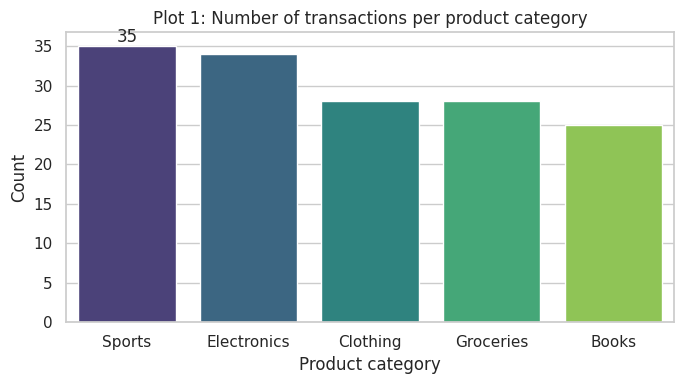

product_category
Sports         23.3
Electronics    22.7
Clothing       18.7
Groceries      18.7
Books          16.7


In [31]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=merged, x="product_category", order=order, palette="viridis")
ax.bar_label(ax.containers[0])
plt.title("Plot 1: Number of transactions per product category")
plt.xlabel("Product category"); plt.ylabel("Count")
save_fig("eda_01_target_distribution")
print((merged["product_category"].value_counts(normalize=True) * 100).round(1).to_string())

**Interpretation:**

The classes are fairly balanced: Sports (23.3%) and Electronics (22.7%) are the largest, Clothing and Groceries have 18.7% each, and Books is the smallest (16.7%). No resampling is needed. A model that always predicts the biggest class would reach only about 23% accuracy (random guessing gives 20%), so macro F1 is reported next to accuracy.

### 6.5 Plot 2 – Purchase amount distribution and by product
The histogram shows the shape of purchase amounts; the box plot compares the amount across products to see whether price helps separate the categories.

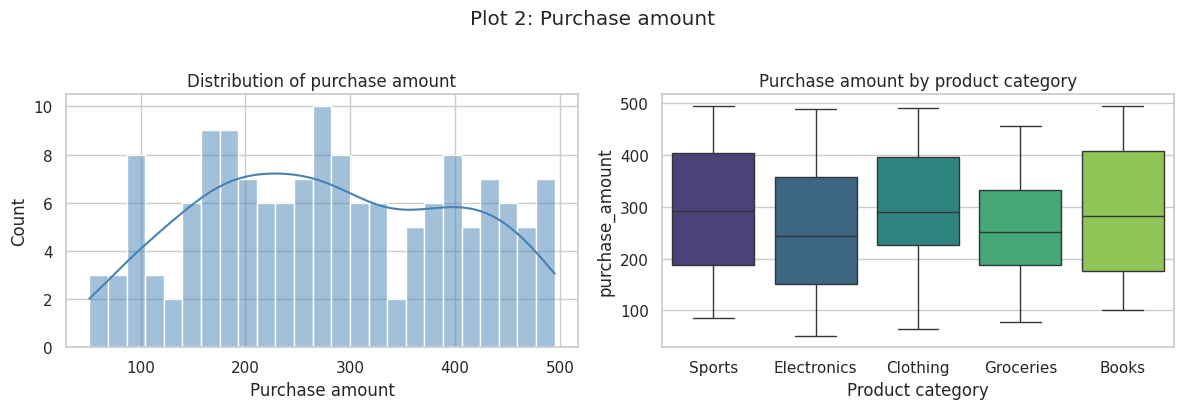

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(merged["purchase_amount"], bins=25, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of purchase amount"); axes[0].set_xlabel("Purchase amount")
sns.boxplot(data=merged, x="product_category", y="purchase_amount", order=order, ax=axes[1], palette="viridis")
axes[1].set_title("Purchase amount by product category"); axes[1].set_xlabel("Product category")
plt.suptitle("Plot 2: Purchase amount", y=1.02)
save_fig("eda_02_purchase_amount")

**Interpretation:**

Purchase amounts are spread fairly evenly between about 50 and 500 instead of forming a bell curve. The boxes for the five products overlap heavily, so the amount alone separates the products only weakly.

### 6.6 Outlier check (IQR rule)
A value is flagged as an outlier if it lies more than 1.5 x IQR below Q1 or above Q3. Also shows the average amount per category.

In [33]:
q1, q3 = merged["purchase_amount"].quantile([.25, .75]); iqr = q3 - q1
n_out = ((merged["purchase_amount"] < q1 - 1.5*iqr) | (merged["purchase_amount"] > q3 + 1.5*iqr)).sum()
print(f"IQR outliers in purchase_amount: {n_out}")
print("\nAverage purchase amount per category:")
print(merged.groupby("product_category")["purchase_amount"].mean().round(1).sort_values().to_string())

IQR outliers in purchase_amount: 0

Average purchase amount per category:
product_category
Electronics    253.3
Groceries      258.4
Sports         290.1
Clothing       302.2
Books          306.1


**Interpretation:**

The IQR rule finds **no outliers**, so no capping or removal is needed. Category averages are similar (Electronics 253, Groceries 258, Sports 290, Clothing 302, Books 306) and the spread within each category is much larger than the differences between them.

### 6.7 Plot 3 – Correlation heatmap
Pearson correlation between numeric variables. Strong correlations can indicate redundant features; correlations with the purchase variables hint at predictive signal.

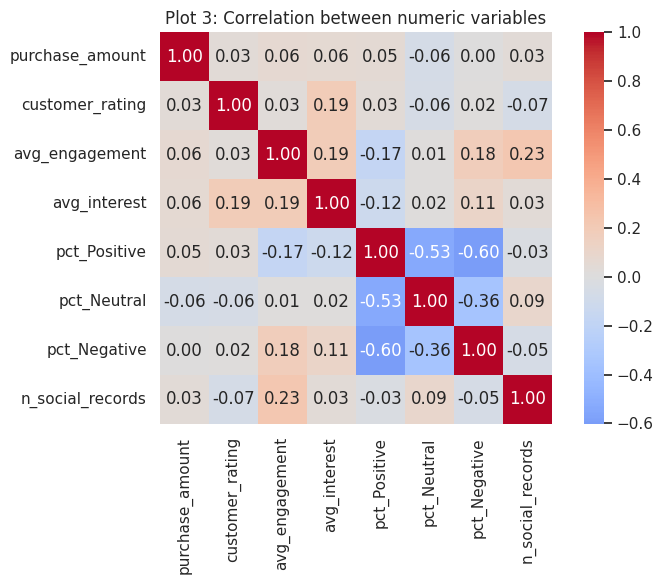

In [34]:
num_cols = ["purchase_amount", "customer_rating", "avg_engagement", "avg_interest",
            "pct_Positive", "pct_Neutral", "pct_Negative", "n_social_records"]
plt.figure(figsize=(8, 6))
sns.heatmap(merged[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Plot 3: Correlation between numeric variables")
save_fig("eda_03_correlation_heatmap")

**Interpretation:**

The strongest correlations are between the sentiment shares (Negative–Positive 0.60, Neutral–Positive 0.53), which is expected because the three shares add up to 1 and therefore carry overlapping information. Every other pair is weak (about 0.23 or less, for example engagement vs number of records 0.23 and interest vs rating 0.19). No numeric feature is strongly related to the purchase amount, so linear relationships are almost absent, which already hints that predicting the product will be difficult.

### 6.8 Plot 4 – Social platform vs. product category
For each customer's main platform, the percentage of purchases in each product category (rows sum to 100%). Shows whether platform and product are related.

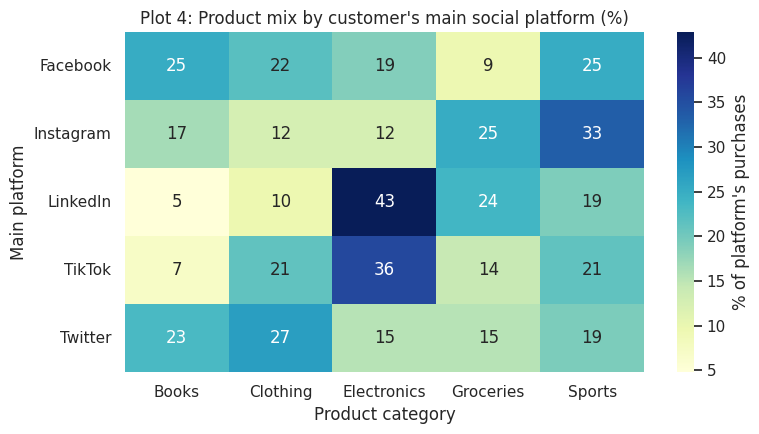

In [35]:
ct = pd.crosstab(has_soc["top_platform"], has_soc["product_category"], normalize="index") * 100
plt.figure(figsize=(8, 4.5))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of platform's purchases"})
plt.title("Plot 4: Product mix by customer's main social platform (%)")
plt.xlabel("Product category"); plt.ylabel("Main platform")
save_fig("eda_04_platform_vs_product")

**Interpretation:**

Some patterns stand out: **LinkedIn (43%) and TikTok (36%)** customers lean towards Electronics, while **Instagram** customers lean towards Sports (33%) and Groceries (25%); Facebook and Twitter are spread more evenly. Each platform has only a few dozen purchases, so these differences could easily be chance and should be treated as hints, not conclusions.

### 6.9 Plot 5 – Rating and purchase interest by product
Do customers rate some products higher, or show higher purchase interest for some products?

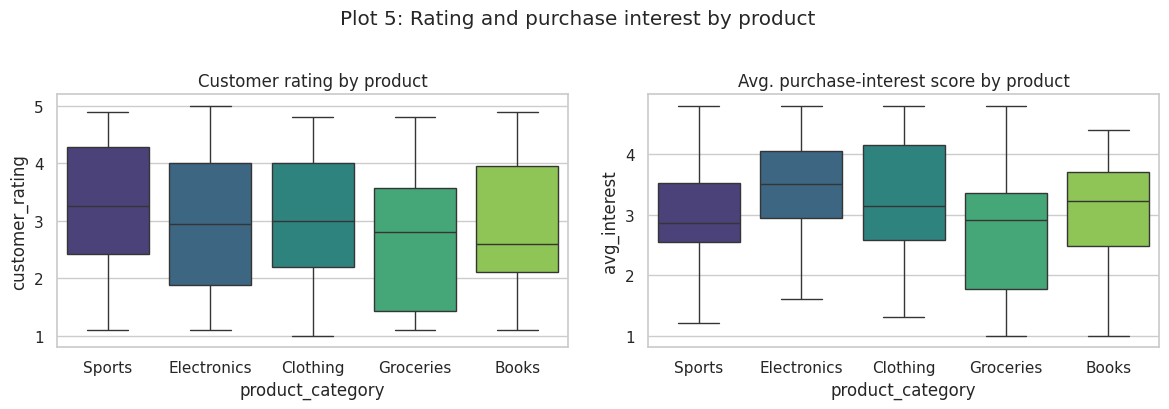

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=merged, x="product_category", y="customer_rating", order=order, ax=axes[0], palette="viridis")
axes[0].set_title("Customer rating by product")
sns.boxplot(data=has_soc, x="product_category", y="avg_interest", order=order, ax=axes[1], palette="viridis")
axes[1].set_title("Avg. purchase-interest score by product")
plt.suptitle("Plot 5: Rating and purchase interest by product", y=1.02)
save_fig("eda_05_rating_interest_by_product")

**Interpretation:**

Ratings are almost identical across products (average 2.7 for Groceries up to 3.2 for Sports), so the rating is not a useful signal for the product. Average purchase interest is highest for Electronics (about 3.5) and lowest for Groceries (about 2.7), but the boxes overlap heavily, so the effect is small.

---
## 7. Feature engineering

**Design decision – avoid leakage.** The model should predict the product a customer will buy *when they visit*. Information that only exists once the purchase has happened (that purchase's amount and rating) would not be available at prediction time. By default the model therefore uses:

| Group | Features |
|---|---|
| Social profile | `avg_engagement`, `avg_interest`, `pct_Positive/Neutral/Negative`, `top_platform`, `n_platforms`, `n_social_records`, `has_social_profile`, `engagement_interest` |
| Time | `purchase_month`, `purchase_weekday`, `is_weekend` |
| Customer history (only *before* the current purchase) | `prev_purchases`, `prev_avg_amount`, `prev_avg_rating`, `prev_<category>` |

A switch, `INCLUDE_CURRENT_TXN_FEATURES`, lets you test adding the current `purchase_amount` and `customer_rating` (see the ablation in Section 9).

### 7.1 Time features
Sort the data chronologically (needed for history features) and extract month, day of week and a weekend flag from the purchase date.

In [37]:
df = merged.sort_values(["purchase_date", "transaction_id"]).reset_index(drop=True)

df["purchase_month"]   = df["purchase_date"].dt.month
df["purchase_weekday"] = df["purchase_date"].dt.dayofweek      # Monday = 0
df["is_weekend"]       = (df["purchase_weekday"] >= 5).astype(int)

display(df[["purchase_date", "purchase_month", "purchase_weekday", "is_weekend"]].head())

,purchase_date,purchase_month,purchase_weekday,is_weekend
0,2024-01-01,1,0,0
1,2024-01-02,1,1,0
2,2024-01-03,1,2,0
3,2024-01-04,1,3,0
4,2024-01-05,1,4,0


**Interpretation:**

The extracted values match the dates: 1 January 2024 gives month 1, weekday 0 (Monday) and a weekend flag of 0. The data covers January to May 2024, one transaction per day.

### 7.2 Social interaction feature
`engagement_interest` multiplies a customer's engagement by their purchase interest (scaled to 0–5), capturing customers who are *both* active and interested.

In [38]:
df["engagement_interest"] = df["avg_engagement"] * df["avg_interest"] / 100
display(df[["avg_engagement", "avg_interest", "engagement_interest"]].dropna().head())

,avg_engagement,avg_interest,engagement_interest
0,71.666667,2.166667,1.552778
1,60.000000,4.300000,2.580000
2,87.000000,4.800000,4.176000
4,72.666667,2.500000,1.816667
5,77.000000,2.666667,2.053333


**Interpretation:**

The new feature behaves as expected: it is larger when both engagement and interest are high (for example 71.7 x 2.17 / 100 = 1.55 for the first row). Rows without a social profile have no value and are imputed later in the pipeline.

### 7.3 Customer history features (leakage-safe)
For each purchase, summarise the customer's **earlier** purchases only: how many there were, their average amount and their average rating. `shift()` excludes the current row so a row never sees its own values.

In [39]:
g = df.groupby("customer_id")
df["prev_purchases"]  = g.cumcount()
df["prev_avg_amount"] = g["purchase_amount"].transform(lambda x: x.shift().expanding().mean())
df["prev_avg_rating"] = g["customer_rating"].transform(lambda x: x.shift().expanding().mean())

# show one customer with several purchases to see how history builds up
example_id = df["customer_id"].value_counts().index[0]
display(df[df["customer_id"] == example_id][["customer_id", "purchase_date", "purchase_amount",
                                             "prev_purchases", "prev_avg_amount", "prev_avg_rating"]])

,customer_id,purchase_date,purchase_amount,prev_purchases,prev_avg_amount,prev_avg_rating
37,161,2024-02-07,333.0,0,NaN,NaN
38,161,2024-02-08,77.0,1,333.000000,2.600000
40,161,2024-02-10,93.0,2,205.000000,2.600000
84,161,2024-03-25,150.0,3,167.666667,1.900000
93,161,2024-04-03,103.0,4,163.250000,2.166667
133,161,2024-05-13,492.0,5,151.200000,1.975000


**Interpretation:**

In the example customer (161), the first purchase has **no history** (NaN, 0 previous purchases). The second shows 1 previous purchase with an average amount of 333, and the history grows with every purchase until the last one, which sees 5 earlier purchases (average amount about 151). Each row only uses earlier purchases.

### 7.4 Previous purchases per category
For each purchase, how many times the customer previously bought each category (Books, Clothing, ...). Again only **earlier** purchases are counted: cumulative sum minus the current row.

In [40]:
cat_dummies = pd.get_dummies(df["product_category"]).astype(int)
prev_cat = cat_dummies.groupby(df["customer_id"]).cumsum() - cat_dummies     # earlier purchases only
prev_cat.columns = [f"prev_{c}" for c in prev_cat.columns]
df = pd.concat([df, prev_cat], axis=1)
PREV_CAT_COLS = list(prev_cat.columns)

display(df[df["customer_id"] == example_id][["purchase_date", "product_category"] + PREV_CAT_COLS])

,purchase_date,product_category,prev_Books,prev_Clothing,prev_Electronics,prev_Groceries,prev_Sports
37,2024-02-07,Clothing,0,0,0,0,0
38,2024-02-08,Groceries,0,1,0,0,0
40,2024-02-10,Electronics,0,1,0,1,0
84,2024-03-25,Sports,0,1,1,1,0
93,2024-04-03,Groceries,0,1,1,1,1
133,2024-05-13,Sports,0,1,1,2,1


**Interpretation:**

For customer 161, the counts only include purchases made **before** each row. The first purchase (Clothing) has all counts at 0; the later Electronics purchase already shows 1 previous Clothing and 1 previous Groceries purchase. The current purchase is never counted.

### 7.5 Leakage sanity checks
Two assertions prove the history features are leakage-safe: a customer's first purchase has no history, and the per-category counts always add up to `prev_purchases`.

In [41]:
first = df.groupby("customer_id").head(1)
assert (first["prev_purchases"] == 0).all() and first["prev_avg_amount"].isna().all()
assert (df[PREV_CAT_COLS].sum(axis=1) == df["prev_purchases"]).all()
print("Leakage checks passed.")
print(f"{(df['prev_purchases'] == 0).mean():.0%} of rows are a customer's first purchase (no history).")

Leakage checks passed.
50% of rows are a customer's first purchase (no history).


**Interpretation:**

The leakage checks passed: a customer's first purchase has no history, and the category counts always add up to the number of previous purchases. However, **50% of the rows are a customer's first purchase**, so half of the data has no purchase history, which limits how useful the history features can be.

### 7.6 Define the feature lists
Chooses which columns feed the model. The switch `INCLUDE_CURRENT_TXN_FEATURES` (default `False`) controls whether the current purchase's amount and rating are used.

In [42]:
INCLUDE_CURRENT_TXN_FEATURES = False     # set True to also use the current purchase_amount / customer_rating

BASE_NUMERIC = ["avg_engagement", "avg_interest", "pct_Positive", "pct_Neutral", "pct_Negative",
                "n_platforms", "n_social_records", "has_social_profile", "engagement_interest",
                "purchase_month", "purchase_weekday", "is_weekend",
                "prev_purchases", "prev_avg_amount", "prev_avg_rating"] + PREV_CAT_COLS
CATEGORICAL = ["top_platform"]

def get_features(include_current=False):
    num = BASE_NUMERIC + (["purchase_amount", "customer_rating"] if include_current else [])
    return num, CATEGORICAL

NUMERIC, CATEGORICAL = get_features(INCLUDE_CURRENT_TXN_FEATURES)
FEATURES = NUMERIC + CATEGORICAL
print(f"{len(FEATURES)} features ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print(FEATURES)

21 features (20 numeric, 1 categorical)
['avg_engagement', 'avg_interest', 'pct_Positive', 'pct_Neutral', 'pct_Negative', 'n_platforms', 'n_social_records', 'has_social_profile', 'engagement_interest', 'purchase_month', 'purchase_weekday', 'is_weekend', 'prev_purchases', 'prev_avg_amount', 'prev_avg_rating', 'prev_Books', 'prev_Clothing', 'prev_Electronics', 'prev_Groceries', 'prev_Sports', 'top_platform']


**Interpretation:**

The model starts with **21 features (20 numeric, 1 categorical)**: social-profile features, time features and customer-history features. The current purchase's amount and rating are left out by default because they would not be known before the purchase happens (see the ablation in 9.12). Section 8 applies a feature selection to this list.

### 7.7 Define the target (y), features (X) and customer groups
The target (`product_category`) is converted to integers with `LabelEncoder`. `groups` holds each row's customer ID, used later so one customer is never in both the training and test sets.

In [43]:
le = LabelEncoder()
y = le.fit_transform(df["product_category"])
groups = df["customer_id"].values
X = df[FEATURES]
CLASSES = list(le.classes_)
n_classes = len(CLASSES)
print("Classes:", dict(zip(range(n_classes), CLASSES)))
print("X shape:", X.shape, "| y length:", len(y))

Classes: {0: 'Books', 1: 'Clothing', 2: 'Electronics', 3: 'Groceries', 4: 'Sports'}
X shape: (150, 21) | y length: 150


**Interpretation:**

The classes are encoded alphabetically: 0 = Books, 1 = Clothing, 2 = Electronics, 3 = Groceries, 4 = Sports. `X` has 150 rows and 21 features, and `y` has 150 labels.

---
## 8. Train / test split (grouped by customer) and feature selection

Customers appear in several transactions. A random row split would put the same customer in both train and test, letting the model "recognise" customers instead of generalising. We therefore split **by customer** (`GroupShuffleSplit`): all transactions of a customer go to either train **or** test. The test set is never used for fitting or imputation.

### 8.1 Split into train and test
80% of customers for training, 20% for testing. The `assert` proves that no customer appears in both sets.

In [44]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

assert set(groups[train_idx]).isdisjoint(set(groups[test_idx]))
print(f"Train: {len(X_train)} rows / {len(set(groups[train_idx]))} customers")
print(f"Test : {len(X_test)} rows / {len(set(groups[test_idx]))} customers  (no customer overlap)")

Train: 125 rows / 60 customers
Test : 25 rows / 15 customers  (no customer overlap)


**Interpretation:**

The data was split **by customer**: 125 training rows from 60 customers and 25 test rows from 15 customers, with no customer in both sets. Splitting by customer stops the model from recognising customers instead of learning general patterns, which would inflate the scores.

### 8.2 Class distribution in train and test
Checks that all five products appear in both sets and how large each class is in the test set (which limits how reliable test metrics can be).

In [45]:
print(pd.DataFrame({"train": pd.Series(le.inverse_transform(y_train)).value_counts(),
                    "test":  pd.Series(le.inverse_transform(y_test)).value_counts()}).fillna(0).astype(int))

             train  test
Books           23     2
Clothing        19     9
Electronics     30     4
Groceries       24     4
Sports          29     6


**Interpretation:**

All five products appear in both sets, but the test set is tiny (Books 2, Clothing 9, Electronics 4, Groceries 4, Sports 6). The mix is also different: Clothing is only 15% of the training rows (19 of 125) but 36% of the test rows (9 of 25). Hold-out scores are therefore very unstable, which is why cross-validation is also used.

### Feature selection (training data only)
Section 7 created the candidate features. Before modelling, we check whether some of them are **useless or redundant**. To avoid leakage, every check below uses the **training set only** – the test set plays no part in deciding which features are kept.

| Rule | What it removes |
|---|---|
| Near-constant | a feature where more than 95% of rows share one value (it cannot separate products) |
| Highly correlated pair | when two features have \|r\| >= 0.85, the one with the **lower mutual information** with the product is dropped (the other carries almost the same information) |

Mutual information (MI) is also shown for every feature. With only ~125 training rows the MI values are noisy, so MI is used **only to break ties** between a correlated pair, never to remove a feature on its own.

### 8.3 Feature diagnostics: missing values and near-constant features
For each numeric feature in the training set: percentage missing, number of unique values, how much of the data is the single most common value, and the standard deviation. Features dominated by one value carry almost no information.

In [46]:
train_num = X_train[NUMERIC]
diag = pd.DataFrame({
    "missing_%": (train_num.isna().mean() * 100).round(1),
    "n_unique": train_num.nunique(),
    "dominant_value_%": train_num.apply(lambda s: s.dropna().value_counts(normalize=True).iloc[0] * 100).round(1),
    "std": train_num.std().round(3),
})
DOMINANT_THRESHOLD = 95
near_constant = diag.index[(diag["dominant_value_%"] > DOMINANT_THRESHOLD) | (diag["std"] == 0)].tolist()

display(diag.sort_values("dominant_value_%", ascending=False))
print(f"Near-constant features (> {DOMINANT_THRESHOLD}% one value):", near_constant or "none")

,missing_%,n_unique,dominant_value_%,std
prev_Clothing,0.0,2,89.6,0.306
prev_Books,0.0,3,88.0,0.416
prev_Electronics,0.0,3,86.4,0.375
prev_Sports,0.0,4,83.2,0.492
has_social_profile,0.0,2,75.2,0.434
prev_Groceries,0.0,3,74.4,0.460
is_weekend,0.0,2,71.2,0.455
pct_Negative,24.8,5,62.8,0.388
pct_Neutral,24.8,5,59.6,0.364
n_platforms,24.8,4,50.0,0.760


Near-constant features (> 95% one value): none


**Interpretation:**

The prior-purchase counts are mostly 0 (74%–90% of rows share one value) because most purchases have no history. `has_social_profile` is 75% one value. No feature exceeds the 95% threshold, so **none is near-constant**. Missing values are highest for `prev_avg_amount` and `prev_avg_rating` (about 48%, first purchases) and the social features (24.8%).

### 8.4 Correlation between features, and highly correlated pairs
A heatmap of the correlations between all numeric features (training data, missing values filled with the training median for this check only), followed by the list of pairs whose absolute correlation is at or above the threshold of 0.85.

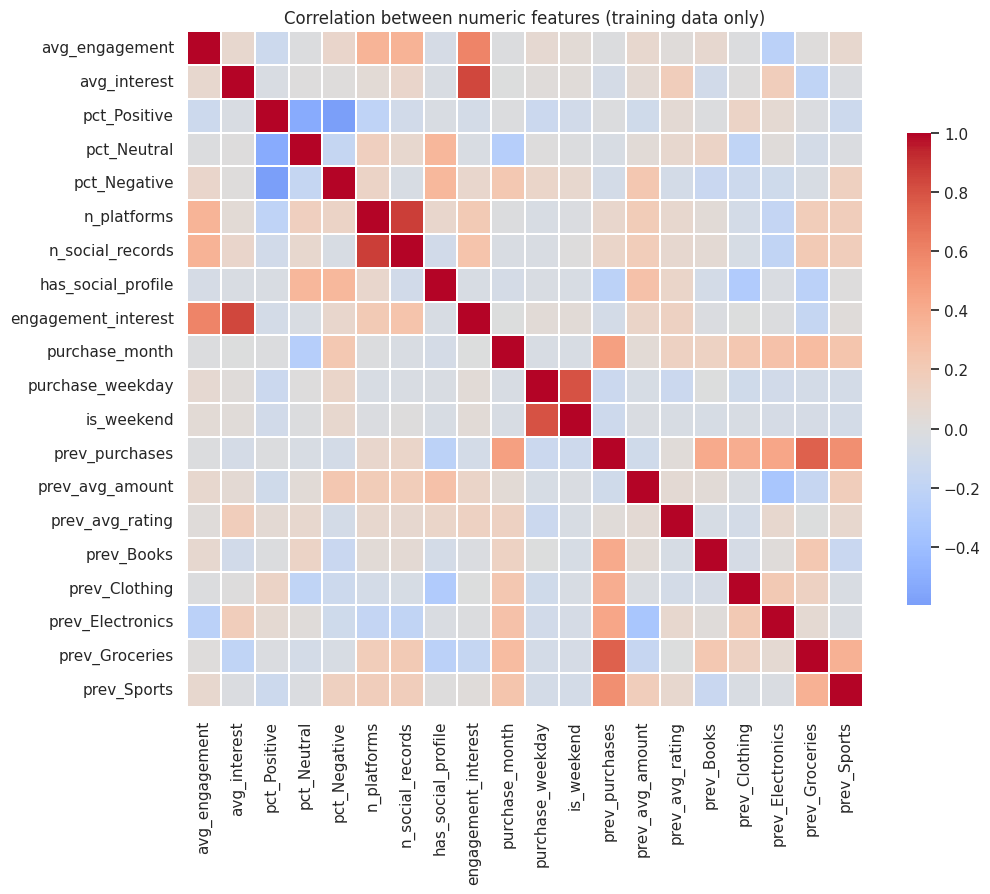

Pairs with |r| >= 0.85:


,a,b,r
85,n_platforms,n_social_records,0.875


In [47]:
train_filled = train_num.fillna(train_num.median())
corr = train_filled.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=.3, cbar_kws={"shrink": .7})
plt.title("Correlation between numeric features (training data only)")
save_fig("fs_01_feature_correlation")

CORR_THRESHOLD = 0.85
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (upper.stack().rename("r").reset_index()
              .rename(columns={"level_0": "a", "level_1": "b"})
              .query("r >= @CORR_THRESHOLD").sort_values("r", ascending=False))
print(f"Pairs with |r| >= {CORR_THRESHOLD}:")
display(high_pairs.round(3) if len(high_pairs) else "none")

**Interpretation:**

Only one pair reaches the 0.85 threshold: **`n_platforms` and `n_social_records` (r = 0.875)**. This is natural, because a customer with more social records tends to appear on more platforms. The other features are much less correlated, so there is little redundancy.

### 8.5 Mutual information with the target
Mutual information measures how much knowing a feature tells us about the product category (0 = nothing). It also captures non-linear relationships. It is computed on the training data only and is used below to decide which feature of a correlated pair to keep.

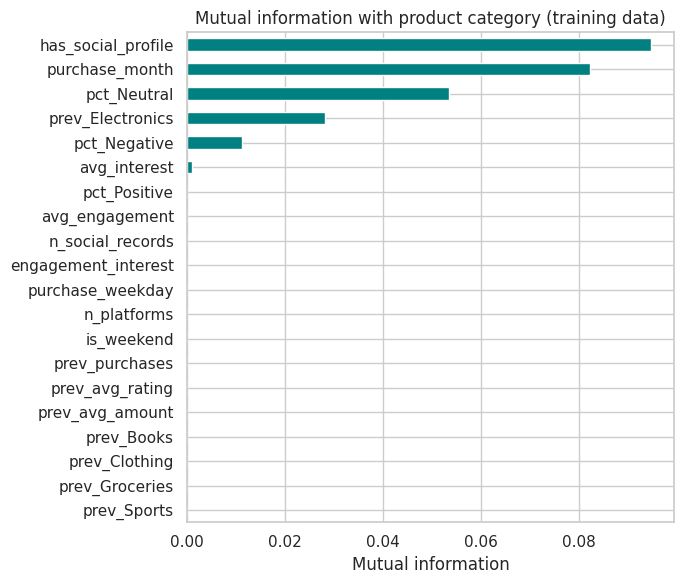

has_social_profile     0.095
purchase_month         0.082
pct_Neutral            0.053
prev_Electronics       0.028
pct_Negative           0.011
avg_interest           0.001
pct_Positive           0.000
avg_engagement         0.000
n_social_records       0.000
engagement_interest    0.000
purchase_weekday       0.000
n_platforms            0.000
is_weekend             0.000
prev_purchases         0.000
prev_avg_rating        0.000
prev_avg_amount        0.000
prev_Books             0.000
prev_Clothing          0.000
prev_Groceries         0.000
prev_Sports            0.000


In [48]:
mi = pd.Series(mutual_info_classif(train_filled, y_train, random_state=RANDOM_STATE),
               index=train_filled.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 6))
mi[::-1].plot(kind="barh", color="teal")
plt.title("Mutual information with product category (training data)")
plt.xlabel("Mutual information")
save_fig("fs_02_mutual_information")
print(mi.round(3).to_string())

**Interpretation:**

Mutual information values are very small: the highest are `has_social_profile` (0.095), `purchase_month` (0.082) and `pct_Neutral` (0.053), and most features are 0. No single feature carries much information about the product. With only 125 training rows these estimates are noisy, so MI is used only as a tie-break and not to remove features on its own.

### 8.6 Decide which features to drop
Applies the two rules: drop near-constant features, and for every highly correlated pair drop the feature with the lower mutual information. Each dropped feature is recorded with its reason, which is useful for the report.

In [49]:
dropped = {c: f"near-constant (> {DOMINANT_THRESHOLD}% one value)" for c in near_constant}

for _, pair in high_pairs.iterrows():
    a, b = pair["a"], pair["b"]
    if a in dropped or b in dropped:
        continue
    keep, drop = (a, b) if mi[a] >= mi[b] else (b, a)
    dropped[drop] = f"|r| = {pair['r']:.2f} with '{keep}' (lower mutual information)"

if dropped:
    display(pd.Series(dropped, name="reason").rename_axis("dropped feature").to_frame())
else:
    print("No features dropped.")

,reason
dropped feature,
n_social_records,|r| = 0.87 with 'n_platforms' (lower mutual in...


**Interpretation:**

Only **`n_social_records`** was dropped, because of its correlation of 0.87 with `n_platforms`. Both features have a mutual information of about 0, so the choice between them is effectively a tie-break (the first of the pair is kept). No feature was removed for being near-constant.

### 8.7 Apply the selection
Removes the dropped features from the feature lists and rebuilds `X`, `X_train` and `X_test`, so every model and the saved prediction function use the **selected** feature set. Rows and the train/test split are unchanged.

In [50]:
BASE_NUMERIC = [c for c in BASE_NUMERIC if c not in dropped]
NUMERIC, CATEGORICAL = get_features(INCLUDE_CURRENT_TXN_FEATURES)
FEATURES = NUMERIC + CATEGORICAL

X = df[FEATURES]
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]

assert not set(dropped) & set(FEATURES)
print(f"Selected {len(FEATURES)} features ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical); dropped {len(dropped)}.")
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Features:", FEATURES)

Selected 20 features (19 numeric, 1 categorical); dropped 1.
X_train: (125, 20) | X_test: (25, 20)
Features: ['avg_engagement', 'avg_interest', 'pct_Positive', 'pct_Neutral', 'pct_Negative', 'n_platforms', 'has_social_profile', 'engagement_interest', 'purchase_month', 'purchase_weekday', 'is_weekend', 'prev_purchases', 'prev_avg_amount', 'prev_avg_rating', 'prev_Books', 'prev_Clothing', 'prev_Electronics', 'prev_Groceries', 'prev_Sports', 'top_platform']


**Interpretation:**

The selected feature set has **20 features (19 numeric, 1 categorical)**, one fewer than before. `X_train` is (125, 20) and `X_test` is (25, 20). The groups are: social (engagement, interest, sentiment shares, `n_platforms`, `has_social_profile`, `engagement_interest`, `top_platform`), time (month, weekday, weekend) and history (previous purchases, average amount, average rating and 5 category counts).

---
## 9. Model training and comparison
Preprocessing lives **inside** each scikit-learn `Pipeline`, so imputation, scaling and encoding are fitted on training data only (no leakage).

### 9.1 Preprocessing function
- **Numeric features:** median imputation (with missing-indicator columns) + standard scaling.
- **Categorical features:** most-frequent imputation + one-hot encoding (unseen categories are ignored).

In [51]:
def make_preprocessor(numeric, categorical):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), numeric),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ])

### 9.2 Candidate models
- **Baseline** – always predicts using class frequencies (any real model must beat this).
- **Logistic Regression** – simple linear model (strongly regularised because the data is small).
- **Random Forest** – ensemble of shallow trees.
- **XGBoost** (or Gradient Boosting if XGBoost is unavailable).

Hyper-parameters are kept conservative to limit overfitting on ~150 rows.

In [52]:
def make_models():
    models = {
        "Baseline (majority class)": DummyClassifier(strategy="prior"),
        "Logistic Regression": LogisticRegression(max_iter=3000, C=0.02, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=8,
                                                random_state=RANDOM_STATE, n_jobs=-1),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBClassifier(n_estimators=60, max_depth=2, learning_rate=0.03, min_child_weight=5,
                                          subsample=0.8, colsample_bytree=0.8,
                                          objective="multi:softprob", eval_metric="mlogloss",
                                          random_state=RANDOM_STATE, n_jobs=1)
    else:
        models["Gradient Boosting"] = GradientBoostingClassifier(n_estimators=60, max_depth=2, min_samples_leaf=8,
                                                                  learning_rate=0.03, random_state=RANDOM_STATE)
    return models

def make_pipeline(model, numeric=None, categorical=None):
    return Pipeline([("prep", make_preprocessor(numeric or NUMERIC, categorical or CATEGORICAL)),
                     ("model", model)])

print("Candidate models:", list(make_models()))

Candidate models: ['Baseline (majority class)', 'Logistic Regression', 'Random Forest', 'XGBoost']


**Interpretation:**

**Baseline:** the reference that always predicts from class frequencies. **Logistic Regression:** simple, interpretable and well suited to small datasets, strongly regularised (`C = 0.02`). **Random Forest:** can capture non-linear effects and interactions, kept shallow (depth 3, at least 8 samples per leaf). **XGBoost:** a boosted-tree model that is strong on tabular data, kept small (60 trees, depth 2) to limit overfitting on about 125 rows.


### 9.3 Evaluation metrics and cross-validation setup
Metrics: **accuracy**, **macro F1** (treats all classes equally) and **log loss** (the "loss"; lower is better). `GroupKFold` keeps every customer inside a single fold. A helper function runs cross-validation for any set of models and features.

In [53]:
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "log_loss": make_scorer(log_loss, greater_is_better=False, response_method="predict_proba",
                            labels=list(range(n_classes))),
}
cv = GroupKFold(n_splits=5)

def run_cv(models, numeric=None, categorical=None):
    rows = []
    for name, model in models.items():
        pipe = make_pipeline(model, numeric, categorical)
        data = X if numeric is None else df[numeric + categorical]
        res = cross_validate(pipe, data, y, groups=groups, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({"model": name,
                     "cv_accuracy": res["test_accuracy"].mean(), "cv_accuracy_std": res["test_accuracy"].std(),
                     "cv_f1_macro": res["test_f1_macro"].mean(), "cv_f1_macro_std": res["test_f1_macro"].std(),
                     "cv_log_loss": -res["test_log_loss"].mean()})
    return pd.DataFrame(rows).set_index("model")

### 9.4 Create the candidate models and a one-model evaluation function
Each model is trained and evaluated **in its own cell** below, so you can run, inspect or re-run any model separately. To keep the comparison fair, every model uses exactly the same:
- train/test split (Section 8) and the same 5 grouped cross-validation folds,
- preprocessing pipeline (Section 9.1),
- metrics and random seed.

`evaluate_model` runs grouped cross-validation on the whole dataset and then a single hold-out evaluation (fit on train, score on test), and stores the results in the `results` dictionary. For reference: random guessing among 5 classes gives 0.20 accuracy and a log loss of ln(5) = 1.609.

In [54]:
MODELS = make_models()
results, fitted = {}, {}

def evaluate_model(name):
    # Cross-validate one model, then fit on the training set and score the hold-out test set.
    cv_row = run_cv({name: MODELS[name]}).iloc[0]

    pipe = make_pipeline(make_models()[name]).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)
    pred = proba.argmax(axis=1)
    fitted[name] = pipe

    results[name] = {**cv_row.to_dict(),
                     "test_accuracy": accuracy_score(y_test, pred),
                     "test_f1_macro": f1_score(y_test, pred, average="macro"),
                     "test_log_loss": log_loss(y_test, proba, labels=list(range(n_classes)))}
    return pd.Series(results[name]).round(3)

print("Models ready:", list(MODELS))
print(f"Random-guess accuracy: {1/n_classes:.2f} | log loss of uniform guessing: {np.log(n_classes):.3f}")

Models ready: ['Baseline (majority class)', 'Logistic Regression', 'Random Forest', 'XGBoost']
Random-guess accuracy: 0.20 | log loss of uniform guessing: 1.609


### 9.5 Model 1 – Baseline (majority class)
Predicts using only the class frequencies in the training data and ignores all features. Any real model must beat this to show that the features contain useful information.

In [55]:
evaluate_model("Baseline (majority class)")

,0
cv_accuracy,0.173
cv_accuracy_std,0.049
cv_f1_macro,0.058
cv_f1_macro_std,0.014
cv_log_loss,1.636
test_accuracy,0.160
test_f1_macro,0.055
test_log_loss,1.657


**Interpretation:**

The baseline gets a cross-validated accuracy of **0.173**, macro F1 **0.058** and log loss **1.636**; on the hold-out set accuracy is 0.16 and F1 0.055. Its F1 is low because it always predicts one class. These are the numbers a useful model must beat.

### 9.6 Model 2 – Logistic Regression
A simple linear model. It is strongly regularised (small `C`) because there are only about 150 rows, which keeps it from memorising noise.

In [56]:
evaluate_model("Logistic Regression")

,0
cv_accuracy,0.227
cv_accuracy_std,0.044
cv_f1_macro,0.189
cv_f1_macro_std,0.036
cv_log_loss,1.680
test_accuracy,0.160
test_f1_macro,0.116
test_log_loss,1.707


**Interpretation:**

Cross-validation: accuracy **0.227 (±0.044)**, macro F1 **0.189 (±0.036)**, log loss **1.680**. It beats the baseline in accuracy and F1 but its log loss is *worse* (1.680 vs 1.636). On the hold-out set it reaches only 0.16 accuracy (the same as the baseline) and 0.116 F1, so the advantage does not clearly carry over.


### 9.7 Model 3 – Random Forest
An ensemble of shallow decision trees. It can capture non-linear effects and interactions, e.g. between platform and engagement.

In [57]:
evaluate_model("Random Forest")

,0
cv_accuracy,0.207
cv_accuracy_std,0.039
cv_f1_macro,0.149
cv_f1_macro_std,0.039
cv_log_loss,1.667
test_accuracy,0.240
test_f1_macro,0.185
test_log_loss,1.694


**Interpretation:**

Cross-validation: accuracy 0.207, macro F1 0.149, log loss 1.667, lower than Logistic Regression. On the hold-out set, however, it is the best model (accuracy 0.24, F1 0.185). The ranking flips between cross-validation and the 25-row test set, which shows that the differences are mostly noise.

### 9.8 Model 4 – XGBoost (or Gradient Boosting)
A boosted-tree model that builds trees one after another, each correcting the previous errors. If XGBoost is not installed, Gradient Boosting is used instead.

In [58]:
boosted_name = [n for n in MODELS if n in ("XGBoost", "Gradient Boosting")][0]
print("Evaluating:", boosted_name)
evaluate_model(boosted_name)

Evaluating: XGBoost


,0
cv_accuracy,0.220
cv_accuracy_std,0.054
cv_f1_macro,0.183
cv_f1_macro_std,0.031
cv_log_loss,1.686
test_accuracy,0.160
test_f1_macro,0.125
test_log_loss,1.718


**Interpretation:**

Cross-validation: accuracy 0.220, macro F1 0.183, log loss 1.686; hold-out accuracy 0.16 and F1 0.125. It performs about the same as Logistic Regression, so the extra complexity of boosting brings no benefit here.

### 9.9 Compare all models and select the best
Combines the stored results into one table (saved for the report) and selects the best non-baseline model by **cross-validated macro F1**.

In [59]:
comparison = pd.DataFrame(results).T
comparison.index.name = "model"
comparison.to_csv(EVAL_DIR / "model_comparison.csv")
display(comparison.round(3))

candidates = comparison.drop(index="Baseline (majority class)")
BEST_NAME = candidates["cv_f1_macro"].idxmax()
print(f"Best model by cross-validated macro F1: {BEST_NAME}")

,cv_accuracy,cv_accuracy_std,cv_f1_macro,cv_f1_macro_std,cv_log_loss,test_accuracy,test_f1_macro,test_log_loss
model,,,,,,,,
Baseline (majority class),0.173,0.049,0.058,0.014,1.636,0.16,0.055,1.657
Logistic Regression,0.227,0.044,0.189,0.036,1.680,0.16,0.116,1.707
Random Forest,0.207,0.039,0.149,0.039,1.667,0.24,0.185,1.694
XGBoost,0.220,0.054,0.183,0.031,1.686,0.16,0.125,1.718


Best model by cross-validated macro F1: Logistic Regression


**Interpretation:**

Logistic Regression was selected on cross-validated macro F1 (0.189 vs 0.183 for XGBoost and 0.149 for Random Forest), but the gap to XGBoost (0.006) is far smaller than the fold-to-fold standard deviation (about 0.03–0.04), so **the models are effectively tied**; Logistic Regression was chosen for its simplicity. All log losses (1.667–1.686) are worse than the baseline (1.636) and uniform guessing (1.609), so none of the models provides reliable probability estimates. The hold-out ranking (Random Forest best) differs from cross-validation.

### 9.10 Ablation (a) – best model WITHOUT the current purchase's amount and rating
Reference result using the default, leakage-safe feature set.

In [60]:
num_wo, cat_wo = get_features(include_current=False)
ab_without = run_cv({BEST_NAME: make_models()[BEST_NAME]}, num_wo, cat_wo)
display(ab_without.round(3))

,cv_accuracy,cv_accuracy_std,cv_f1_macro,cv_f1_macro_std,cv_log_loss
model,,,,,
Logistic Regression,0.227,0.044,0.189,0.036,1.68


### 9.11 Ablation (b) – best model WITH the current purchase's amount and rating
Same model, but also given the amount and rating of the purchase itself (information that would not be available before the purchase).

In [61]:
num_with, cat_with = get_features(include_current=True)
ab_with = run_cv({BEST_NAME: make_models()[BEST_NAME]}, num_with, cat_with)
display(ab_with.round(3))

,cv_accuracy,cv_accuracy_std,cv_f1_macro,cv_f1_macro_std,cv_log_loss
model,,,,,
Logistic Regression,0.24,0.09,0.196,0.08,1.694


### 9.12 Ablation – side-by-side comparison
Does using the current-purchase features improve the results? If not, the leakage-safe feature set loses nothing.

In [62]:
ablation = pd.concat([ab_without.assign(feature_set="Without current-purchase features (default)"),
                      ab_with.assign(feature_set="With current purchase_amount + rating")]).set_index("feature_set")
display(ablation.round(3))

,cv_accuracy,cv_accuracy_std,cv_f1_macro,cv_f1_macro_std,cv_log_loss
feature_set,,,,,
Without current-purchase features (default),0.227,0.044,0.189,0.036,1.680
With current purchase_amount + rating,0.240,0.090,0.196,0.080,1.694


**Interpretation:**

Adding the current purchase's amount and rating gives slightly higher accuracy (0.240 vs 0.227) and F1 (0.196 vs 0.189), but the standard deviation doubles (0.090 vs 0.044) and the log loss gets worse (1.694 vs 1.680). The small gains are inside the noise, so there is **no evidence that these features help**. The leakage-safe default feature set is justified, and it is the only one available at prediction time.

### Additional evaluation: is the model really better than chance?
With only ~150 rows, a single cross-validation run is noisy. The next four steps strengthen the evaluation:

| Step | Question it answers |
|---|---|
| 9.13–9.14 Repeated cross-validation | Are the model scores stable when the customer folds are reshuffled several times? |
| 9.15 Top-k accuracy | A recommender can show several products – is the right one among the top 2 or top 3? |
| 9.16 Permutation test | Is the model's score distinguishable from what we would get with *random* labels? |

### 9.13 Helper for repeated, stratified, customer-grouped cross-validation
`repeated_group_cv` repeats 5-fold cross-validation with **different random seeds**. `StratifiedGroupKFold` keeps every customer inside a single fold *and* keeps the product mix similar in each fold. For every fold it records accuracy, macro F1, log loss and top-1/2/3 accuracy. The optional `y_target` argument lets us pass shuffled labels later for the permutation test. No output.

In [63]:
def repeated_group_cv(name, seeds=range(5), y_target=None):
    yy = y if y_target is None else y_target
    labels = list(range(n_classes))
    rows = []
    for seed in seeds:
        skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (tr, te) in enumerate(skf.split(X, yy, groups)):
            pipe = make_pipeline(make_models()[name]).fit(X.iloc[tr], yy[tr])
            proba = pipe.predict_proba(X.iloc[te])
            pred = proba.argmax(axis=1)
            rows.append({"seed": seed, "fold": fold,
                         "accuracy": accuracy_score(yy[te], pred),
                         "f1_macro": f1_score(yy[te], pred, average="macro"),
                         "log_loss": log_loss(yy[te], proba, labels=labels),
                         "top1": top_k_accuracy_score(yy[te], proba, k=1, labels=labels),
                         "top2": top_k_accuracy_score(yy[te], proba, k=2, labels=labels),
                         "top3": top_k_accuracy_score(yy[te], proba, k=3, labels=labels)})
    return pd.DataFrame(rows)

### 9.14 Repeated cross-validation for all models
Runs the helper for every model (5 seeds x 5 folds = 25 evaluations each) and reports the **mean and standard deviation** of accuracy, macro F1 and log loss. Compare these with random guessing: accuracy 0.20 and log loss 1.609.

In [64]:
rep_results = {name: repeated_group_cv(name) for name in MODELS}

rep_summary = pd.DataFrame({
    name: {"accuracy": r["accuracy"].mean(), "accuracy_std": r["accuracy"].std(),
           "f1_macro": r["f1_macro"].mean(), "f1_macro_std": r["f1_macro"].std(),
           "log_loss": r["log_loss"].mean(), "log_loss_std": r["log_loss"].std()}
    for name, r in rep_results.items()}).T
rep_summary.index.name = "model"
rep_summary.to_csv(EVAL_DIR / "repeated_cv_summary.csv")
display(rep_summary.round(3))
print(f"Random guessing: accuracy {1/n_classes:.2f} | log loss {np.log(n_classes):.3f}")

,accuracy,accuracy_std,f1_macro,f1_macro_std,log_loss,log_loss_std
model,,,,,,
Baseline (majority class),0.178,0.061,0.059,0.018,1.641,0.037
Logistic Regression,0.231,0.066,0.191,0.053,1.661,0.066
Random Forest,0.216,0.066,0.163,0.061,1.664,0.057
XGBoost,0.208,0.079,0.168,0.064,1.671,0.052


Random guessing: accuracy 0.20 | log loss 1.609


**Interpretation:**

With 5 seeds x 5 folds, Logistic Regression remains on top in accuracy (**0.231**) and macro F1 (**0.191**), followed by Random Forest (0.216 / 0.163) and XGBoost (0.208 / 0.168); the baseline has 0.178 / 0.059. The standard deviations (0.05–0.08) are larger than the differences between the models. All log losses (1.661–1.671) remain worse than the baseline (1.641). The result agrees with the single cross-validation in 9.9.

### 9.15 Top-k accuracy
A product recommender normally shows **several** suggestions. Top-k accuracy is the share of cases where the purchased product is among the model's *k* highest-probability products. Random guessing gives k/5 (0.20, 0.40, 0.60 for k = 1, 2, 3), so those are the numbers to beat. Results come from the repeated cross-validation above.

,top-1,top-2,top-3
Baseline (majority class),0.178,0.416,0.587
Logistic Regression,0.231,0.417,0.612
Random Forest,0.216,0.383,0.583
XGBoost,0.208,0.396,0.602
Random guessing,0.200,0.400,0.600


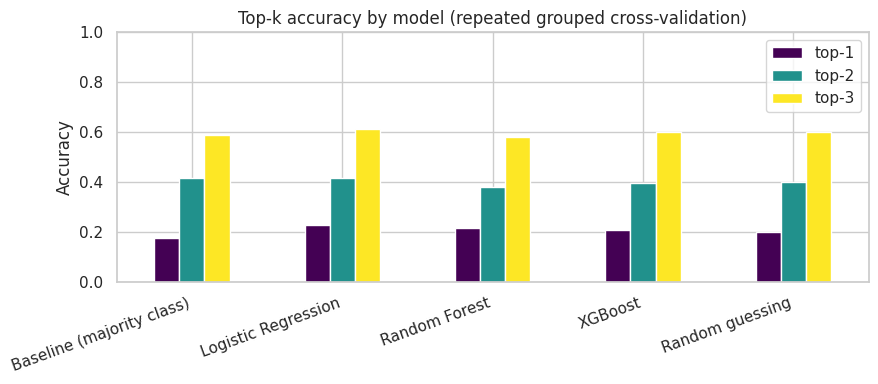

In [65]:
topk = pd.DataFrame({name: [r[f"top{k}"].mean() for k in (1, 2, 3)] for name, r in rep_results.items()},
                    index=["top-1", "top-2", "top-3"]).T
topk.loc["Random guessing"] = [k / n_classes for k in (1, 2, 3)]
topk.to_csv(EVAL_DIR / "topk_accuracy.csv")
display(topk.round(3))

topk.plot(kind="bar", figsize=(9, 4), colormap="viridis")
plt.title("Top-k accuracy by model (repeated grouped cross-validation)")
plt.ylabel("Accuracy"); plt.xticks(rotation=20, ha="right"); plt.ylim(0, 1)
save_fig("model_topk_accuracy")

**Interpretation:**

No model meaningfully beats random guessing at any k: Logistic Regression reaches top-1 0.231, top-2 0.417 and top-3 0.612, against 0.20, 0.40 and 0.60 for random guessing (and 0.178 / 0.416 / 0.587 for the baseline). At top-3 the gain is only 0.012. Showing several suggestions would therefore not make the recommendations reliably better with this data.

### 9.16 Permutation test: is the model better than chance?
We shuffle the product labels (which destroys any real link between features and product), re-run the **same** cross-validation, and record the score. Repeating this many times shows the range of scores a model gets by luck alone. If the real score falls inside that range, the model is **not distinguishable from chance**.

The p-value is the share of shuffled runs that scored at least as high as the real model: p < 0.05 would indicate real signal. The real score is the average over 5 seeds, while each shuffled run uses one seed, which makes the test slightly conservative. Change `N_PERMUTATIONS` for a finer estimate (it takes longer to run).

accuracy  | real 0.231 | shuffled mean 0.202 | shuffled 95th percentile 0.277 | p-value 0.290
f1_macro  | real 0.191 | shuffled mean 0.165 | shuffled 95th percentile 0.233 | p-value 0.323


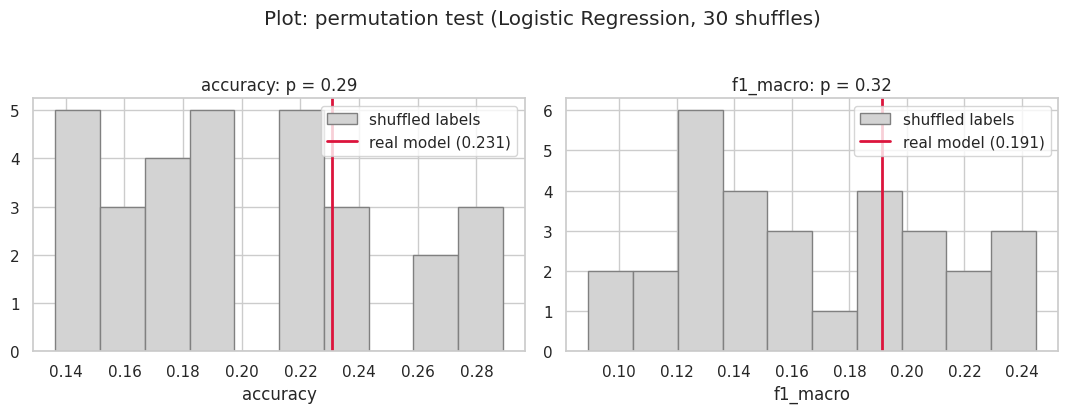

In [66]:
N_PERMUTATIONS = 30
rng = np.random.default_rng(RANDOM_STATE)

perm_rows = []
for i in range(N_PERMUTATIONS):
    r = repeated_group_cv(BEST_NAME, seeds=[0], y_target=rng.permutation(y))
    perm_rows.append({"accuracy": r["accuracy"].mean(), "f1_macro": r["f1_macro"].mean()})
perm = pd.DataFrame(perm_rows)

real = rep_results[BEST_NAME][["accuracy", "f1_macro"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["accuracy", "f1_macro"]):
    ax.hist(perm[metric], bins=10, color="lightgray", edgecolor="gray", label="shuffled labels")
    ax.axvline(real[metric], color="crimson", linewidth=2, label=f"real model ({real[metric]:.3f})")
    p = (1 + (perm[metric] >= real[metric]).sum()) / (N_PERMUTATIONS + 1)
    ax.set_title(f"{metric}: p = {p:.2f}"); ax.set_xlabel(metric); ax.legend()
    print(f"{metric:9s} | real {real[metric]:.3f} | shuffled mean {perm[metric].mean():.3f} | "
          f"shuffled 95th percentile {perm[metric].quantile(.95):.3f} | p-value {p:.3f}")
plt.suptitle(f"Plot: permutation test ({BEST_NAME}, {N_PERMUTATIONS} shuffles)", y=1.03)
save_fig("model_permutation_test")

**Interpretation:**

The real scores lie inside the range produced by shuffled labels: accuracy 0.231 vs a shuffled mean of 0.202 (95th percentile 0.277), p = 0.29; macro F1 0.191 vs 0.165 (95th percentile 0.233), p = 0.32. Both p-values are above 0.05, so the model is **not distinguishable from chance** and the features show no detectable signal for the product. This is consistent with the weak correlations and mutual information seen earlier. With 30 shuffles, the p-values are approximate.

---
## 10. Final evaluation of the selected model
A closer look at the selected model on the hold-out test set: per-class metrics, the confusion matrix and the most influential features.

### 10.1 Predictions of the selected model
Retrieve the fitted pipeline for the selected model and compute predicted probabilities and classes for the test set. No output.

In [67]:
best_pipe = fitted[BEST_NAME]
proba = best_pipe.predict_proba(X_test)
pred = proba.argmax(axis=1)

### 10.2 Classification report
Precision, recall and F1 for each product, plus overall accuracy and macro/weighted averages. Remember that each class has only a few test examples.

In [68]:
print(f"Selected model: {BEST_NAME}\n")
print(classification_report(y_test, pred, labels=list(range(n_classes)), target_names=CLASSES, zero_division=0))

Selected model: Logistic Regression

              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         2
    Clothing       0.00      0.00      0.00         9
 Electronics       0.30      0.75      0.43         4
   Groceries       0.00      0.00      0.00         4
      Sports       0.14      0.17      0.15         6

    accuracy                           0.16        25
   macro avg       0.09      0.18      0.12        25
weighted avg       0.08      0.16      0.11        25



**Interpretation:**

Overall accuracy on the 25 hold-out rows is **0.16** and macro F1 0.12. Only Electronics is predicted with some success (recall 0.75, precision 0.30, F1 0.43, based on 4 examples); Sports has F1 0.15; Books, Clothing (9 examples) and Groceries are never predicted correctly. With 2–9 examples per class these numbers are very unstable and should not be over-interpreted.

### 10.3 Confusion matrix
Rows are the true product, columns the predicted product. A strong model shows a clear diagonal.

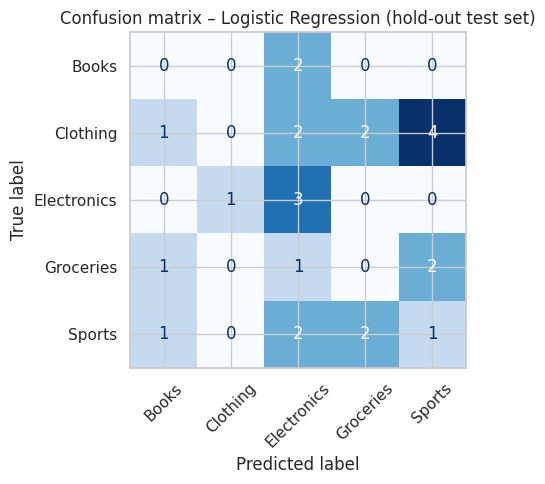

In [69]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=range(n_classes)), display_labels=CLASSES
                       ).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"Confusion matrix – {BEST_NAME} (hold-out test set)")
save_fig("model_confusion_matrix")

**Interpretation:**

There is no clear diagonal. Predictions pile up on Electronics (10 of 25 predictions): 3 of 4 true Electronics are correct, but many Clothing, Groceries and Sports purchases are also predicted as Electronics. Clothing (9 test rows) is almost never predicted, and Sports is right only once in 6. This is consistent with weak signal.

### 10.4 Feature importance
Which input features the selected model relies on most (tree importance or absolute coefficient size, depending on the model).

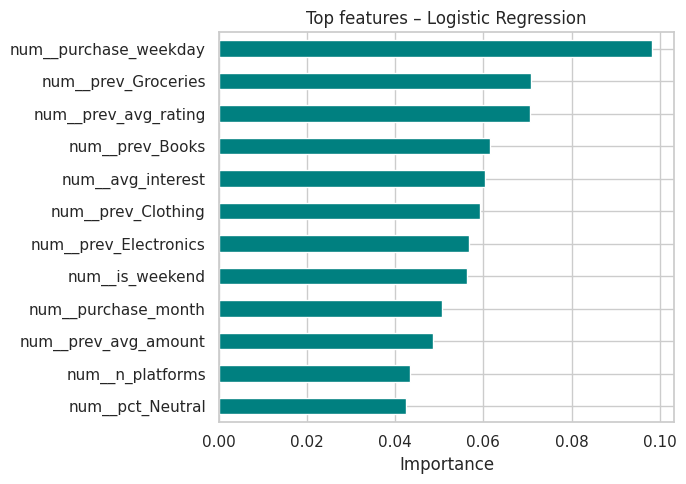

In [70]:
model = best_pipe.named_steps["model"]
names = best_pipe.named_steps["prep"].get_feature_names_out()
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=names)
elif hasattr(model, "coef_"):
    imp = pd.Series(np.abs(model.coef_).mean(axis=0), index=names)
else:
    imp = None

if imp is not None:
    top = imp.sort_values(ascending=False).head(12)[::-1]
    plt.figure(figsize=(7, 5))
    top.plot(kind="barh", color="teal")
    plt.title(f"Top features – {BEST_NAME}"); plt.xlabel("Importance")
    save_fig("model_feature_importance")

**Interpretation:**

The importance values are small and fairly flat: the top features are `purchase_weekday` (about 0.10), `prev_Groceries`, `prev_avg_rating`, `prev_Books` and `avg_interest` (about 0.06–0.07), a mix of time, history and social features. No feature dominates, and the high rank of the weekday, which has no sensible link to the product here, suggests the model is partly fitting noise. The ranking is descriptive and does not show what drives purchases.


---
## 11. Save outputs and the `predict_product()` interface

The saved model is **refitted on all available data** (the cross-validation and hold-out numbers above remain the honest performance estimates).


### 11.1 Save the merged and engineered dataset
This is the "merged dataset with feature engineering" required in the GitHub repository.

In [71]:
df.to_csv(PROCESSED_DIR / "merged_customer_data.csv", index=False)
print("Saved:", PROCESSED_DIR / "merged_customer_data.csv", "| shape:", df.shape)

Saved: /content/drive/MyDrive/formative2/data/processed/merged_customer_data.csv | shape: (150, 27)


**Interpretation:**

The merged and engineered dataset was saved to `data/processed/merged_customer_data.csv` in the Drive project folder: **150 rows and 27 columns** (the original transaction columns, the aggregated social features and the engineered features).

### 11.2 Refit the selected model on all data and save it
Saves a bundle containing the fitted pipeline, the label encoder (to turn predictions back into product names) and the feature list, so the demo app can load everything from one file.

In [72]:
final_pipe = make_pipeline(make_models()[BEST_NAME]).fit(X, y)
bundle = {"pipeline": final_pipe, "label_encoder": le, "feature_columns": FEATURES,
          "numeric": NUMERIC, "categorical": CATEGORICAL, "model_name": BEST_NAME,
          "classes": CLASSES, "prev_cat_cols": PREV_CAT_COLS}
joblib.dump(bundle, MODEL_DIR / "product_model.joblib")
print("Saved:", MODEL_DIR / "product_model.joblib", "| model:", BEST_NAME)

Saved: /content/drive/MyDrive/formative2/models/product_model.joblib | model: Logistic Regression


### 11.3 Save the final metrics for the report
Writes the selected model's cross-validation and hold-out metrics to a JSON file so the numbers in the report match the notebook.

In [73]:
best_row = comparison.loc[BEST_NAME]
final_metrics = {"selected_model": BEST_NAME,
                 "cv_accuracy": round(float(best_row["cv_accuracy"]), 4),
                 "cv_f1_macro": round(float(best_row["cv_f1_macro"]), 4),
                 "cv_log_loss": round(float(best_row["cv_log_loss"]), 4),
                 "test_accuracy": round(float(best_row["test_accuracy"]), 4),
                 "test_f1_macro": round(float(best_row["test_f1_macro"]), 4),
                 "test_log_loss": round(float(best_row["test_log_loss"]), 4),
                 "n_rows": int(len(df)), "n_features": len(FEATURES)}
(EVAL_DIR / "product_model_metrics.json").write_text(json.dumps(final_metrics, indent=2))
print(json.dumps(final_metrics, indent=2))

{
  "selected_model": "Logistic Regression",
  "cv_accuracy": 0.2267,
  "cv_f1_macro": 0.1885,
  "cv_log_loss": 1.6798,
  "test_accuracy": 0.16,
  "test_f1_macro": 0.1165,
  "test_log_loss": 1.7074,
  "n_rows": 150,
  "n_features": 20
}


**Interpretation:**

Selected model: **Logistic Regression**, trained on 150 rows with 20 features. Cross-validation: accuracy 0.2267, macro F1 0.1885, log loss 1.6798. Hold-out: accuracy 0.16, macro F1 0.1165, log loss 1.7074. These numbers go into the report together with the caveat that they are close to chance level.

### 11.4 Helper: build one customer's feature row
When the app knows *which customer* was verified, this helper rebuilds that customer's features from everything known about them (social profile + purchase history) in the same format used for training.

> When integrating, copy this helper and `predict_product` (next cell) into `src/product_model.py`.

In [74]:
def build_inference_row(customer_id, bundle, as_of=None):
    """Build one feature row for a customer using everything known about them so far."""
    cust_tx = trans[trans["customer_id"] == customer_id].sort_values("purchase_date")
    soc = social_agg[social_agg["customer_id"] == customer_id]
    if cust_tx.empty and soc.empty:
        raise ValueError(f"Customer {customer_id} not found in transactions or social profiles.")

    as_of = pd.Timestamp(as_of) if as_of is not None else trans["purchase_date"].max() + pd.Timedelta(days=1)
    row = {c: np.nan for c in bundle["feature_columns"]}

    if len(soc):
        s = soc.iloc[0]
        for c in ["avg_engagement", "avg_interest", "pct_Positive", "pct_Neutral", "pct_Negative",
                  "n_platforms", "n_social_records"]:
            row[c] = s[c]
        row["top_platform"] = s["top_platform"]
        row["has_social_profile"] = 1
        row["engagement_interest"] = s["avg_engagement"] * s["avg_interest"] / 100
    else:
        row["top_platform"] = "Unknown"
        row["has_social_profile"] = 0

    row["purchase_month"] = as_of.month
    row["purchase_weekday"] = as_of.dayofweek
    row["is_weekend"] = int(as_of.dayofweek >= 5)
    row["prev_purchases"] = len(cust_tx)
    row["prev_avg_amount"] = cust_tx["purchase_amount"].mean() if len(cust_tx) else np.nan
    row["prev_avg_rating"] = cust_tx["customer_rating"].mean() if len(cust_tx) else np.nan
    for c in bundle["prev_cat_cols"]:
        row[c] = int((cust_tx["product_category"] == c.replace("prev_", "", 1)).sum())
    # only needed if the model was trained with the current-purchase features
    if "purchase_amount" in row: row["purchase_amount"] = row["prev_avg_amount"]
    if "customer_rating" in row:  row["customer_rating"]  = row["prev_avg_rating"]
    return pd.DataFrame([row])[bundle["feature_columns"]]

### 11.5 `predict_product(customer_id)` – the interface used by the demo app
Loads the saved model, builds the customer's feature row and returns the predicted product with its probability and the full probability table. The app calls this **only after the face and voice checks succeed**.

In [75]:
def predict_product(customer_id, model_path=None, as_of=None):
    bundle = joblib.load(model_path or (MODEL_DIR / "product_model.joblib"))
    X_new = build_inference_row(customer_id, bundle, as_of)
    proba = bundle["pipeline"].predict_proba(X_new)[0]
    order_ = np.argsort(proba)[::-1]
    return {"customer_id": int(customer_id),
            "predicted_product": bundle["classes"][order_[0]],
            "confidence": round(float(proba[order_[0]]), 3),
            "probabilities": {bundle["classes"][i]: round(float(proba[i]), 3) for i in order_}}

### 11.6 Test `predict_product` on three kinds of customers
Checks that the function works for a customer found in **both** files, in **transactions only**, and in **social only**.

In [76]:
both       = sorted(t_ids & s_ids)[0]
trans_only = sorted(t_ids - s_ids)[0]
soc_only   = sorted(s_ids - t_ids)[0]
for label, cid in [("in both files", both), ("transactions only", trans_only), ("social only", soc_only)]:
    print(f"[{label}]", predict_product(cid))

[in both files] {'customer_id': 100, 'predicted_product': 'Clothing', 'confidence': 0.294, 'probabilities': {'Clothing': 0.294, 'Books': 0.215, 'Sports': 0.199, 'Electronics': 0.189, 'Groceries': 0.102}}
[transactions only] {'customer_id': 108, 'predicted_product': 'Books', 'confidence': 0.247, 'probabilities': {'Books': 0.247, 'Sports': 0.219, 'Electronics': 0.195, 'Clothing': 0.178, 'Groceries': 0.161}}
[social only] {'customer_id': 109, 'predicted_product': 'Clothing', 'confidence': 0.234, 'probabilities': {'Clothing': 0.234, 'Sports': 0.211, 'Electronics': 0.206, 'Books': 0.178, 'Groceries': 0.17}}


**Interpretation:**

The function works for all three kinds of customers: both files (customer 100, Clothing, 0.294), transactions only (108, Books, 0.247) and social only (109, Clothing, 0.234, which uses defaults for the missing purchase history). The confidence is only 0.23–0.29, barely above the 0.20 of a uniform guess, so the command-line app should present the result as a low-confidence recommendation.

---
## 12. Summary, limitations and hand-off



### What was done
Both datasets were cleaned (5 duplicate social rows removed, text standardised, types fixed) and linked through the customer ID (`A178` mapped to 178). Because customers have several transactions and several social records, the social data was aggregated to one row per customer before a validated left join, which kept all 150 transactions (a naive join would have produced 246 rows). After EDA, leakage-safe features (social, time and prior-purchase history) were engineered and a training-only feature selection dropped one redundant feature (`n_social_records`), leaving 20 features. A baseline, Logistic Regression, Random Forest and XGBoost were compared using customer-grouped cross-validation (also repeated with 5 seeds), a grouped hold-out test, top-k accuracy and a permutation test.

&nbsp;

### Key results
Logistic Regression was selected. Cross-validated accuracy is 0.227, macro F1 0.189 and log loss 1.680; on the 25-row hold-out set accuracy is 0.16, macro F1 0.117 and log loss 1.707. The baseline scores 0.173 accuracy, 0.058 macro F1 and 1.636 log loss, and random guessing gives 0.20 accuracy and 1.609 log loss. The model is slightly above the baseline in accuracy and F1 but not in log loss, and the permutation test (p about 0.3) shows it cannot be distinguished from chance.

&nbsp;

### Limitations
The dataset is very small (150 transactions, 75 customers), 22% of the rows have no social profile and 50% of the rows have no purchase history. The features show almost no relationship with the product (weak correlations and mutual information), the hold-out set has only 25 rows, and differences between the models are smaller than the fold-to-fold variation. The saved model is a demonstration component and not a validated recommender; its predictions have low confidence (about 0.23–0.29).

&nbsp;

### Files produced
| File | Path |
|---|---|
| Merged + engineered dataset | `data/processed/merged_customer_data.csv` |
| Trained model bundle | `models/product_model.joblib` |
| Model comparison table | `outputs/evaluation/model_comparison.csv` |
| Final metrics (for the report) | `outputs/evaluation/product_model_metrics.json` |
| EDA and evaluation figures | `outputs/figures/*.png` |

### Possible next steps
Collect more transactions per customer, add more informative features (for example product or customer details), tune hyper-parameters with nested cross-validation, calibrate the predicted probabilities and increase the number of permutations to get a more precise p-value.